# Lista de Exercícios 05
## Métodos de Determinação de Raízes

**Programa:** PPGMC / UESC  
**Base:** Burden & Faires — Capítulo 2  

---

## Objetivos

- formular numericamente o problema $f(x)=0$;
- visualizar raízes de funções;
- implementar o **método da bisseção**;
- implementar o **método do ponto fixo**;
- comparar convergência e divergência;
- discutir critérios de parada e erro.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Exercício 1

No notebook disponibilizado para a Aula 7, se faz uso da função `bissecao` que possui o seguinte cabeçalho: 

```python
def bissecao(f, a, b, tol=1e-8, max_iter=100)
```

A função é importada do arquivo pyNuMeth.py que funciona como um módulo python.
Em sala de aula apresentamos o pseudo código, extraído do Burden, para implementação deste algoritmo.

<img src="figuras/bissecao.png" alt="Método da Bisseção" width="600">

Crie seu próprio módulo pyNuMeth.py e implemente nele sua versão do método da bisseção. 



In [3]:
from pyNuMeth import bissecao, bissecao_com_historico, bissecao_criterios_com_historico

## Exercício 2

Use o método da bisseção para encontrar $p_3$ para $f(x) = \sqrt{x} - \cos{x} = 0$ no intervalo $[0, 1]$.

O método falhou após atingir o limite de 3 iterações.

Valor aproximado: p3 = 0.625
f(raiz): -0.020393704463123052


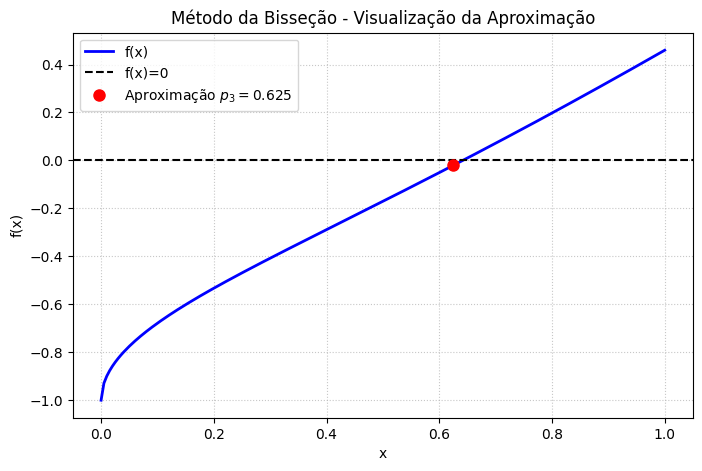

In [4]:
def f(x):
    return np.sqrt(x) - np.cos(x)

a = 0
b = 1
p3 = bissecao(f, a, b, max_iter=3)

print(f"\nValor aproximado: p3 = {p3}")
print(f'f(raiz): {f(p3)}')

x_vals = np.linspace(0, 1, 200)
y_vals = f(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label=r'f(x)', color='blue', linewidth=2)
plt.axhline(0, color='black', linewidth=1.5, linestyle='--', label='f(x)=0')
plt.plot(p3, f(p3), 'ro', markersize=8, label=f'Aproximação $p_3 = {p3}$')
plt.title('Método da Bisseção - Visualização da Aproximação')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

O aviso de "falha" retornado pela saída do código é o esperado. Como Estabelecemos  a execução com apenas max_iter=3 para encontrar  o p3 exigido, o algoritmo foi forçado a parar muito antes de ter a chance de atingir a tolerância padrão da função.

Ainda assim, é interessante notar a eficiência inicial do método. Com apenas 3 passos, a nossa aproximação p3 = 0.625 já entrega um resíduo consideravelmente pequeno. Olhando para a plotagem, vemos que o ponto vermelho já está praticamente colado na raiz verdadeira no eixo x, confirmando que a convergência está perfeitamente encaminhada.

---

## Exercício 3

Utilize o método da bisseção para encontrar soluções com precisão de $10^{-5}$ para os seguintes problemas.

a) $x - 2^{-x} = 0$ para $0 \leq x \leq 1$

b) $x \cos{x} - 2x^2 + 3x - 1 = 0$ para $0.2 \leq x \leq 0.3$ 

PROBLEMA 3(a): Raiz aproximada = 0.641182
f(raiz) = -5.49e-06
-> Iterações TEÓRICAS necessárias: 17
-> Iterações REAIS executadas:   17


,iter,a,b,c,f(c),erro_Intervalo
12,13,0.641113,0.641357,0.641235,0.000072,0.000122
13,14,0.641113,0.641235,0.641174,-0.000017,0.000061
14,15,0.641174,0.641235,0.641205,0.000028,0.000031
15,16,0.641174,0.641205,0.641190,0.000006,0.000015
16,17,0.641174,0.641190,0.641182,-0.000005,0.000008



PROBLEMA 3(b): Raiz aproximada = 0.297528
f(raiz) = -5.78e-06
-> Iterações TEÓRICAS necessárias: 14
-> Iterações REAIS executadas:   14


,iter,a,b,c,f(c),erro_Intervalo
9,10,0.297461,0.297656,0.297559,0.000076,0.000098
10,11,0.297461,0.297559,0.297510,-0.000055,0.000049
11,12,0.297510,0.297559,0.297534,0.000011,0.000024
12,13,0.297510,0.297534,0.297522,-0.000022,0.000012
13,14,0.297522,0.297534,0.297528,-0.000006,0.000006


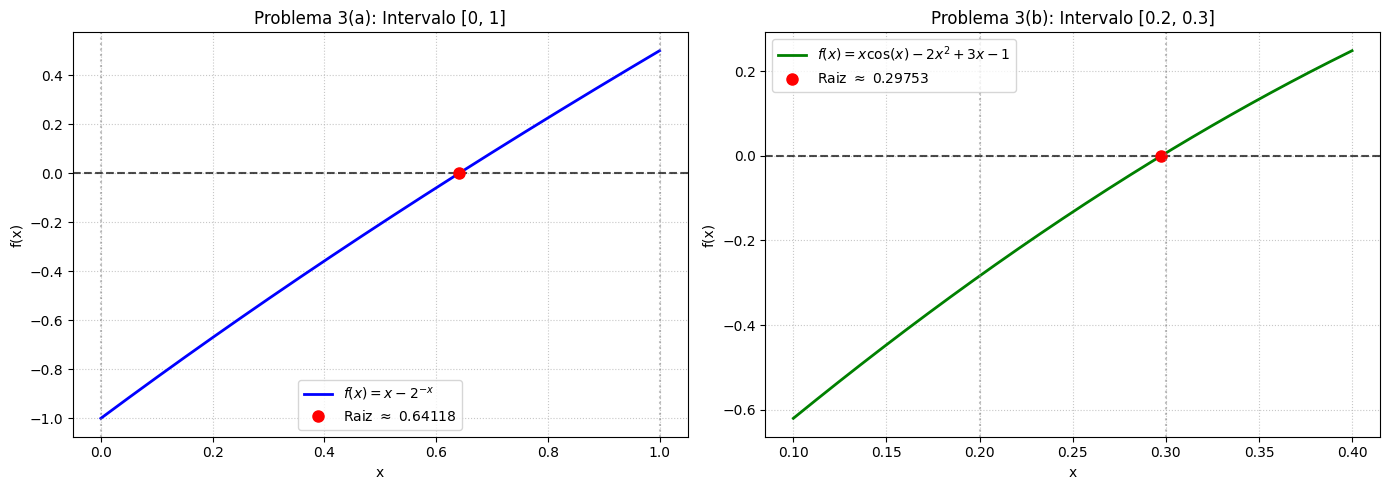

In [5]:
def f_a(x):
    return x - 2**(-x)

def f_b(x):
    return x * np.cos(x) - 2*x**2 + 3*x - 1

def estimativa_iteracoes(a, b, tol):
    n = np.log((b - a) / tol) / np.log(2)
    return int(np.ceil(n))

tolerancia = 1e-5

a_a, b_a = 0, 1
a_b, b_b = 0.2, 0.3

n_teorico_a = estimativa_iteracoes(a_a, b_a, tolerancia)
n_teorico_b = estimativa_iteracoes(a_b, b_b, tolerancia)

raiz_a, hist_a = bissecao_com_historico(f_a, a_a, b_a, tol=tolerancia)
raiz_b, hist_b = bissecao_com_historico(f_b, a_b, b_b, tol=tolerancia)

print("="*60)
print(f"PROBLEMA 3(a): Raiz aproximada = {raiz_a:.6f}")
print(f"f(raiz) = {f_a(raiz_a):.2e}")
print(f"-> Iterações TEÓRICAS necessárias: {n_teorico_a}")
print(f"-> Iterações REAIS executadas:   {len(hist_a['iter'])}")
print("="*60)
df_a = pd.DataFrame(hist_a)
display(df_a.tail()) 

print("\n" + "="*60)
print(f"PROBLEMA 3(b): Raiz aproximada = {raiz_b:.6f}")
print(f"f(raiz) = {f_b(raiz_b):.2e}")
print(f"-> Iterações TEÓRICAS necessárias: {n_teorico_b}")
print(f"-> Iterações REAIS executadas:   {len(hist_b['iter'])}")
print("="*60)
df_b = pd.DataFrame(hist_b)
display(df_b.tail())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5)) 

x_a = np.linspace(0, 1, 200)
ax1.plot(x_a, f_a(x_a), 'b-', linewidth=2, label=r'$f(x) = x - 2^{-x}$')
ax1.axhline(0, color='black', linestyle='--', alpha=0.7)
ax1.plot(raiz_a, f_a(raiz_a), 'ro', markersize=8, label=f'Raiz $\\approx$ {raiz_a:.5f}')
ax1.axvline(0, color='gray', linestyle=':', alpha=0.5) 
ax1.axvline(1, color='gray', linestyle=':', alpha=0.5) 
ax1.set_title('Problema 3(a): Intervalo [0, 1]')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend()

x_b = np.linspace(0.1, 0.4, 200) 
ax2.plot(x_b, f_b(x_b), 'g-', linewidth=2, label=r'$f(x) = x\cos(x) - 2x^2 + 3x - 1$')
ax2.axhline(0, color='black', linestyle='--', alpha=0.7)
ax2.plot(raiz_b, f_b(raiz_b), 'ro', markersize=8, label=f'Raiz $\\approx$ {raiz_b:.5f}')
ax2.axvline(0.2, color='gray', linestyle=':', alpha=0.5) 
ax2.axvline(0.3, color='gray', linestyle=':', alpha=0.5) 
ax2.set_title('Problema 3(b): Intervalo [0.2, 0.3]')
ax2.set_xlabel('x')
ax2.set_ylabel('f(x)')
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

Olhando para as tabelas, fica clara a característica mais marcante do método da bisseção: ele é extremamente confiável, mas o preço que pagamos por isso é o tempo. Como a lógica dele é puramente geométrica, ir cortando o intervalo de busca pela metade a cada passo, o trabalho que ele vai ter depende quase que exclusivamente do tamanho da janela inicial que a gente entrega para ele.

*   No Problema 3(a), demos a ele um espaço relativamente folgado para procurar (o intervalo entre $0$ e $1$, com tamanho $1$). Para fazer essa janela encolher até bater na  tolerância de $10^{-5}$, o algoritmo precisou dar 17 passos até finalmente encontrar a raiz $x \approx 0.641182$, passos esperados por conda do cálculo teórico do número de interações.
*   Já no Problema 3(b) o intervalo sugerido ($[0.2, 0.3]$) já era bem mais estreito, com apenas $0.1$ de largura. Com esse atalho, o método economizou trabalho e encontrou a aproximação de $x \approx 0.297528$ um pouco mais rápido, em 14 iterações.


---

## Exercício 4

No passo 4 do algoritmo da bisseção, apresentado no Exercício 1 podem ser utilizados outros critérios de parada. Por exemplo, dado um valor $\epsilon > 0$ podemos gerar uma sequência de aproximações $p_1, p_2, \dots, p_N$ até que uma das seguintes condições seja satisfeita:

$$
\left | P_N - P_{N-1} \right | < \epsilon, 
$$

$$
\frac{\left | P_N - P_{N-1} \right |}{\left | P_N \right |} < \epsilon,
$$

$$
\left | f(P_N) \right | < \epsilon.
$$

Crie uma versão da função `bissecao` que permita selecionar entre cada um destes três critérios de parada. Avalie o resultado do Exercício 3.a com cada um dos critérios e discuta o resultado. 

In [6]:
def f_a(x):
    return x - 2**(-x)

tolerancia = 1e-5

raiz_1, hist_1 = bissecao_criterios_com_historico(f_a, 0, 1, tol=tolerancia, criterio=1)
df_1 = pd.DataFrame(hist_1)
print("="*60)
print(f"CRITÉRIO 1: Diferença Absoluta |Pn - Pn-1| < {tolerancia}")
print(f"Raiz: {raiz_1:.6f} | Iterações: {len(df_1)}")
display(df_1.tail()) 

raiz_2, hist_2 = bissecao_criterios_com_historico(f_a, 0, 1, tol=tolerancia, criterio=2)
df_2 = pd.DataFrame(hist_2)
print("\n" + "="*60)
print(f"CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < {tolerancia}")
print(f"Raiz: {raiz_2:.6f} | Iterações: {len(df_2)}")
display(df_2.tail())

raiz_3, hist_3 = bissecao_criterios_com_historico(f_a, 0, 1, tol=tolerancia, criterio=3)
df_3 = pd.DataFrame(hist_3)
print("\n" + "="*60)
print(f"CRITÉRIO 3: Valor da Função |f(Pn)| < {tolerancia}")
print(f"Raiz: {raiz_3:.6f} | Iterações: {len(df_3)}")
display(df_3.tail())

CRITÉRIO 1: Diferença Absoluta |Pn - Pn-1| < 1e-05
Raiz: 0.641182 | Iterações: 17


,iter,a,b,c,f(c),valor_criterio
12,13,0.641113,0.641357,0.641235,0.000072,0.000122
13,14,0.641113,0.641235,0.641174,-0.000017,0.000061
14,15,0.641174,0.641235,0.641205,0.000028,0.000031
15,16,0.641174,0.641205,0.641190,0.000006,0.000015
16,17,0.641174,0.641190,0.641182,-0.000005,0.000008



CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < 1e-05
Raiz: 0.641186 | Iterações: 18


,iter,a,b,c,f(c),valor_criterio
13,14,0.641113,0.641235,0.641174,-1.650718e-05,0.000095
14,15,0.641174,0.641235,0.641205,2.757348e-05,0.000048
15,16,0.641174,0.641205,0.641190,5.533185e-06,0.000024
16,17,0.641174,0.641190,0.641182,-5.486988e-06,0.000012
17,18,0.641182,0.641190,0.641186,2.310095e-08,0.000006



CRITÉRIO 3: Valor da Função |f(Pn)| < 1e-05
Raiz: 0.641190 | Iterações: 16


,iter,a,b,c,f(c),valor_criterio
11,12,0.641113,0.641602,0.641357,0.000248,0.000248
12,13,0.641113,0.641357,0.641235,0.000072,0.000072
13,14,0.641113,0.641235,0.641174,-0.000017,0.000017
14,15,0.641174,0.641235,0.641205,0.000028,0.000028
15,16,0.641174,0.641205,0.641190,0.000006,0.000006


Analisando as tabelas, vemos na prática como a escolha do critério de parada muda o comportamento do algoritmo. Embora os três métodos apontem para a mesma vizinhança da raiz ($\approx 0.641$), cada um enxerga a convergência de uma perspectiva diferente:

*   Critério 1 (Diferença Absoluta - 17 iterações): É a abordagem mais clássica e conservadora. Ele olha puramente para a geometria do eixo $x$, garantindo que a incerteza sobre a posição da raiz (o tamanho do passo) seja menor que a nossa tolerância. Exigiu 17 cortes no intervalo para chegar lá.
*   Critério 2 (Diferença Relativa - 18 iterações): Este foi o critério mais rigoroso para este problema, cobrando uma iteração extra. O motivo foi: como a nossa raiz está na casa de $0.64$ (um número menor que 1), dividir o erro absoluto por $0.64$ acaba inflando o valor numérico avaliado. É uma métrica indispensável quando não sabemos a escala do problema (como ao lidar com raízes gigantescas ou minúsculas), mas aqui acabou atrasando um pouco a parada.
*   Critério 3 (Resíduo da Função - 16 iterações): Foi o método mais rápido. Em vez de medir a distância no eixo $x$, ele olha para o eixo $y$ e verifica se o valor da função já esmagou contra o zero. A vantagem é a rapidez, mas ele pode falhar qunado a curva da função for muito suave (plana) cruzando o eixo, o valor de $f(x)$ pode bater a tolerância muito antes de o $x$ estar perto da raiz exata.

---

## Exercício 5

No notebook disponibilizado para a Aula 7, se faz uso da função `ponto_fixo` que possui o seguinte cabeçalho: 

```python
def ponto_fixo(g, x0, tol=1e-8, max_iter=100):
```

A função é importada do arquivo pyNuMeth.py que funciona como um módulo python.
Em sala de aula apresentamos o pseudo código, extraído do Burden, para implementação deste algoritmo.

<img src="figuras/pontoFixo_01.png" alt="Método do Ponto Fixo" width="600">

<img src="figuras/pontoFixo_02.png" alt="Método do Ponto Fixo" width="600">

Modifique seu módulo pyNuMeth.py e implemente nele sua versão do método do ponto fixo. 

In [7]:
from pyNuMeth import ponto_fixo, ponto_fixo_com_historico

Em sala de aula comentamos sobre as condições de existência e unicidade do problema de ponto fixo. 

__Teorema__: Se $g \in C[a, b]$ e $g(x) \in [a, b]$ para todo $ x \in [a, b]$, então $g$ tem pelo menos um ponto fixo em $[a, b]$.

Se, além disso, $g'(x)$ existe em $(a, b)$ e existe uma constante positiva $k < 1$ com 

$$
\left | g'(x) \right |  \leq k, \,\,\, \text{para todo} \,\,\, x \in (a, b), 
$$

então existe exatamente um ponto fixo em $[a, b]$.

__Teorema__: Seja $g \in C[a, b]$ tal que $g(x) \in [a, b]$, para todo $x \in [a, b]$. Suponha, além disso, que $g'$ exista em $(a, b)$ e que exista uma constante $0 < k < 1$ com

$$
\left | g'(x) \right | \leq k, \,\,\, \text{para todo} \,\,\, x \in (a,b).
$$

Então, para qualquer número $p_0$ em $[a, b]$, a sequência definida por

$$
P_n = g(p_{n-1}), \,\,\, n \geq 1,
$$

converge para o único ponto fixo $p$ em $[a, b]$.

__Corolário__: Se $g$ satisfaz as hipóteses do __Teorema__ anterior, então os limites para o erro envolvido no uso de $p_n$ para aproximar $p$ são dados por

$$
\left | p_n - p \right | \leq k^n \, \text{max} \left\{ p_0 - a, b - p_0 \right\}
$$

e 

$$
\left | p_n - p \right | \leq \frac{k^n}{1 - k} \left | p_1 - p_0 \right |\, 
$$

Recomendação: Vejam as demostrações destes teoremas, que podem ser encontradas no Capítulo 2 do Burden.

---

## Exercício 6

Use manipulação algébrica para mostrar que cada uma das seguintes funções tem um ponto fixo em $p$ precisamente quando $f(p) = 0$, onde $f(x) = x^4 + 2x^2 - x - 3$.

a) $g_1(x) = (3+x-2x^2)^{1/4}$

b) $g_2(x) = \left ( \frac{x + 3 - x^4}{2} \right ) ^{1/2}$

c) $g_3(x) = \left ( \frac{x +3}{x^2 + 2} \right ) ^ {1/2}$

d) $g_4(x) = \frac{3x^4 + 2x^2 + 3}{4x^3 + 4x - 1}$

Um ponto $p$ é considerado um ponto fixo de uma função $g(x)$ se, e somente se, **$g(p) = p$**. 
Para provar a relação pedida, vamos igualar cada $g(x)$ a $x$ e manipular a expressão algebricamente para tentar chegar à equação original $f(x) = x^4 + 2x^2 - x - 3 = 0$.

**a) $g_1(x) = (3+x-2x^2)^{1/4}$**
$$x = (3+x-2x^2)^{1/4}$$
Elevando ambos os lados à quarta potência:
$$x^4 = 3 + x - 2x^2$$
Reorganizando os termos:
$$x^4 + 2x^2 - x - 3 = 0 \quad \Rightarrow \quad f(x) = 0$$

**b) $g_2(x) = \left ( \frac{x + 3 - x^4}{2} \right ) ^{1/2}$**
$$x = \left ( \frac{x + 3 - x^4}{2} \right ) ^{1/2}$$
Elevando ao quadrado:
$$x^2 = \frac{x + 3 - x^4}{2}$$
Multiplicando por 2 e reorganizando:
$$2x^2 = x + 3 - x^4$$
$$x^4 + 2x^2 - x - 3 = 0 \quad \Rightarrow \quad f(x) = 0$$

**c) $g_3(x) = \left ( \frac{x +3}{x^2 + 2} \right ) ^ {1/2}$**
$$x = \left ( \frac{x +3}{x^2 + 2} \right ) ^ {1/2}$$
Elevando ao quadrado:
$$x^2 = \frac{x + 3}{x^2 + 2}$$
Multiplicando cruzado:
$$x^2(x^2 + 2) = x + 3$$
$$x^4 + 2x^2 = x + 3$$
$$x^4 + 2x^2 - x - 3 = 0 \quad \Rightarrow \quad f(x) = 0$$

**d) $g_4(x) = \frac{3x^4 + 2x^2 + 3}{4x^3 + 4x - 1}$**
$$x = \frac{3x^4 + 2x^2 + 3}{4x^3 + 4x - 1}$$
Multiplicando cruzado:
$$x(4x^3 + 4x - 1) = 3x^4 + 2x^2 + 3$$
$$4x^4 + 4x^2 - x = 3x^4 + 2x^2 + 3$$
Subtraindo o lado direito do lado esquerdo:
$$(4x^4 - 3x^4) + (4x^2 - 2x^2) - x - 3 = 0$$
$$x^4 + 2x^2 - x - 3 = 0 \quad \Rightarrow \quad f(x) = 0$$



---

## Exercício 7

Realize quatro iterações, se possível, em cada uma das funções $g$ definidas no Exercício anterior. Seja $p_0 = 1$ e $p_{n+1} = g(p_n)$, para $n = 0, 1,2, 3$. Qual função você acha que fornece a melhor aproximação para a solução?

RAIZ DE REFERÊNCIA (Via Bisseção): 1.1241230294

FUNÇÃO g1(x)
Avaliando a derivada na raiz  -->  |g1'(p)| = 0.6154


,iter,x_anterior,x_novo,erro
0,1,1.000000,1.189207,0.189207
1,2,1.189207,1.080058,0.109149
2,3,1.080058,1.149671,0.069614
3,4,1.149671,1.107821,0.041851



FUNÇÃO g2(x)
Avaliando a derivada na raiz  -->  |g2'(p)| = 1.0413


,iter,x_anterior,x_novo,erro
0,1,1.000000,1.224745,0.224745
1,2,1.224745,0.993666,0.231079
2,3,0.993666,1.228569,0.234902
3,4,1.228569,0.987506,0.241062



FUNÇÃO g3(x)
Avaliando a derivada na raiz  -->  |g3'(p)| = 0.2509


,iter,x_anterior,x_novo,erro
0,1,1.000000,1.154701,0.154701
1,2,1.154701,1.116427,0.038273
2,3,1.116427,1.126052,0.009625
3,4,1.126052,1.123639,0.002413



FUNÇÃO g4(x)
Avaliando a derivada na raiz  -->  |g4'(p)| = 0.0000


,iter,x_anterior,x_novo,erro
0,1,1.000000,1.142857,1.428571e-01
1,2,1.142857,1.124482,1.837545e-02
2,3,1.124482,1.124123,3.585261e-04
3,4,1.124123,1.124123,1.342358e-07


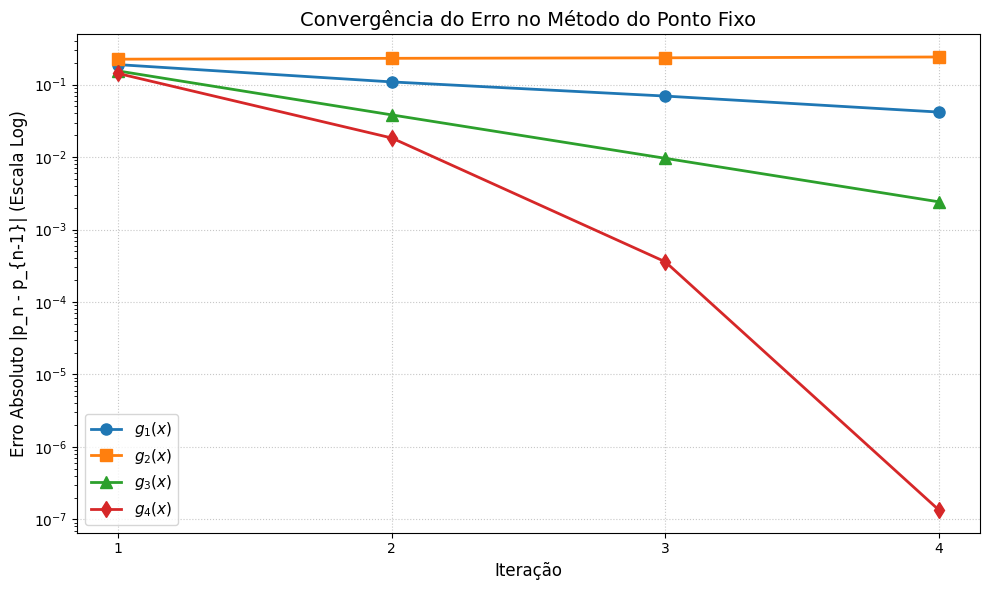

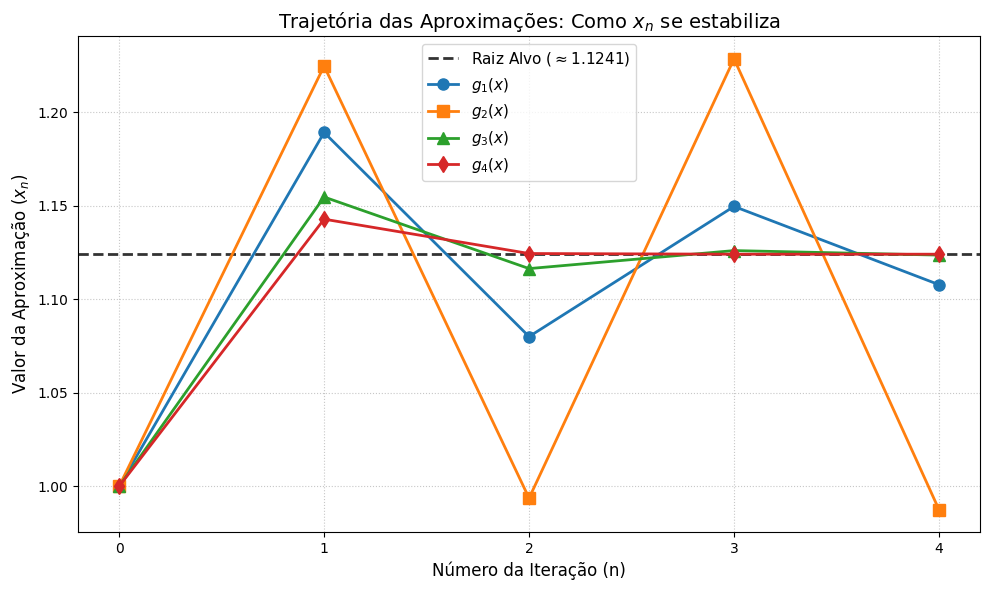

In [22]:
def f_original(x): 
    return x**4 + 2*x**2 - x - 3


raiz_alvo, _ = bissecao_com_historico(f_original, 1, 2)

print("="*60)
print(f"RAIZ DE REFERÊNCIA (Via Bisseção): {raiz_alvo:.10f}")
print("="*60 + "\n")


def g1(x): return (3 + x - 2*x**2)**(1/4)
def g2(x): return ((x + 3 - x**4) / 2)**(1/2)
def g3(x): return ((x + 3) / (x**2 + 2))**(1/2)
def g4(x): return (3*x**4 + 2*x**2 + 3) / (4*x**3 + 4*x - 1)

def dg1(x): 
    return (1 - 4*x) / (4 * (3 + x - 2*x**2)**(0.75))

def dg2(x): 
    return (1 - 4*x**3) / (2 * ((2*x + 6 - 2*x**4))**(0.5))

def dg3(x): 
    return (-x**2 - 6*x + 2) / (2 * (x**3 + 3*x**2 + 2*x + 6)**(0.5)*(x**2 + 2))

def dg4(x):
    du = 12*x**3 + 4*x
    dv = 12*x**2 + 4
    u = 3*x**4 + 2*x**2 + 3
    v = 4*x**3 + 4*x - 1
    return (du*v - u*dv) / (v**2)


p0 = 1
max_it = 4

print("="*50 + "\nFUNÇÃO g1(x)")
print(f"Avaliando a derivada na raiz  -->  |g1'(p)| = {abs(dg1(raiz_alvo)):.4f}")
_, hist_1 = ponto_fixo_com_historico(g1, p0, max_iter=max_it)
display(pd.DataFrame(hist_1))

print("\n" + "="*50 + "\nFUNÇÃO g2(x)")
print(f"Avaliando a derivada na raiz  -->  |g2'(p)| = {abs(dg2(raiz_alvo)):.4f}")
_, hist_2 = ponto_fixo_com_historico(g2, p0, max_iter=max_it)
display(pd.DataFrame(hist_2))

print("\n" + "="*50 + "\nFUNÇÃO g3(x)")
print(f"Avaliando a derivada na raiz  -->  |g3'(p)| = {abs(dg3(raiz_alvo)):.4f}")
_, hist_3 = ponto_fixo_com_historico(g3, p0, max_iter=max_it)
display(pd.DataFrame(hist_3))

print("\n" + "="*50 + "\nFUNÇÃO g4(x)")
print(f"Avaliando a derivada na raiz  -->  |g4'(p)| = {abs(dg4(raiz_alvo)):.4f}")
_, hist_4 = ponto_fixo_com_historico(g4, p0, max_iter=max_it)
display(pd.DataFrame(hist_4))

plt.figure(figsize=(10, 6))
plt.plot(hist_1['iter'], hist_1['erro'], 'o-', linewidth=2, markersize=8, label=r"$g_1(x)$")
plt.plot(hist_2['iter'], hist_2['erro'], 's-', linewidth=2, markersize=8, label=r"$g_2(x)$")
plt.plot(hist_3['iter'], hist_3['erro'], '^-', linewidth=2, markersize=8, label=r"$g_3(x)$")
plt.plot(hist_4['iter'], hist_4['erro'], 'd-', linewidth=2, markersize=8, label=r"$g_4(x)$")
plt.yscale("log")

plt.title('Convergência do Erro no Método do Ponto Fixo', fontsize=14)
plt.xlabel('Iteração', fontsize=12)
plt.ylabel('Erro Absoluto |p_n - p_{n-1}| (Escala Log)', fontsize=12)
plt.xticks(range(1, max_it + 1))
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.axhline(raiz_alvo, color='black', linestyle='--', linewidth=2, alpha=0.8, label=f'Raiz Alvo ($\\approx {raiz_alvo:.4f}$)')

iters = [0] + list(hist_1['iter'])
x_g1 = [p0] + list(hist_1['x_novo'])
x_g2 = [p0] + list(hist_2['x_novo'])
x_g3 = [p0] + list(hist_3['x_novo'])
x_g4 = [p0] + list(hist_4['x_novo'])

plt.plot(iters, x_g1, 'o-', linewidth=2, markersize=8, label=r"$g_1(x)$")
plt.plot(iters, x_g2, 's-', linewidth=2, markersize=8, label=r"$g_2(x)$")
plt.plot(iters, x_g3, '^-', linewidth=2, markersize=8, label=r"$g_3(x)$")
plt.plot(iters, x_g4, 'd-', linewidth=2, markersize=8, label=r"$g_4(x)$")

plt.title('Trajetória das Aproximações: Como $x_n$ se estabiliza', fontsize=14)
plt.xlabel('Número da Iteração (n)', fontsize=12)
plt.ylabel('Valor da Aproximação ($x_n$)', fontsize=12)
plt.xticks(range(0, max_it + 1))
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11, loc='best')
plt.tight_layout()
plt.show()

Esses quatro cenários mostram o quanto o Método do Ponto Fixo é sensível à forma como escolhemos a função de iteração. O sucesso (ou fracasso) depende inteiramente do comportamento da derivada da função perto da raiz ($|g'(x)| < 1$).

*   $g_4(x)$: No gráfico de erro logarítmico, a linha dela despenca. Já na 4ª iteração, o erro está na casa de $10^{-7}$. Isso ocorre porque ela é gerada pelo Método de Newton-Raphson. Ela praticamente alcança a raiz exata logo no segundo passo, como fica evidente no gráfico de trajetória.
*   $g_3(x)$: Ela caminha na direção certa de forma suave, sem sustos. O erro cai de forma consistente, mas, se comparada à $g_4$, ela é lenta. Precisaria de muitas outras iterações para atingir a mesma precisão.
*   $g_1(x)$: Ela está convergindo, mas no gráfico de trajetória a linha fica "ziguezagueando" cruzando a linha preta tracejada. A cada passo, ela pula para cima e depois para baixo do alvo. Ela vai chegar na raiz, mas com mais dificuldade.
*   $g_2(x)$ : Nela o erro está aumentando a cada iteração ($0.22 \rightarrow 0.23 \rightarrow 0.24$). A linha laranja no gráfico de trajetória mostra o ponto sendo empurrado para longe da raiz alvo. Aqui, a derivada $|g_2'(x)|$ é maior que 1, o que transforma a raiz em um ponto de repulsão.

Logo, a função $g_4(x)$ é a que fornece a melhor aproximação.

---

## Exercício 8

No notebook disponibilizado para a Aula 8, se faz uso da função `newton` que possui o seguinte cabeçalho: 

```python

def newton(f, df, x0, tol=1e-10, max_iter=50):

```

A função é importada do arquivo pyNuMeth.py que funciona como um módulo python.
Em sala de aula apresentamos o pseudo código, extraído do Burden, para implementação deste algoritmo.

<img src="figuras/newton.png" alt="Método do Ponto Fixo" width="600">

Modifique seu módulo pyNuMeth.py e implemente nele sua versão do método de Newton.

In [9]:
from pyNuMeth import newton, newton_com_historico, newton_criterios

---

## Exercício 9
Utilize o método de Newton para encontrar soluções com precisão de $10^{-5}$ para os os dois problemas apresentados no Exercício 3. Compare as soluções criando o gráfico que mostre a convergência dos métodos.


PROBLEMA 3(a) - Método de Newton
Raiz encontrada: 0.641186


,iter,x,f(x),f'(x),x_next,erro
0,1,0.500000,-2.071068e-01,1.490129,0.638986,1.389858e-01
1,2,0.638986,-3.178425e-03,1.445114,0.641185,2.199428e-03
2,3,0.641185,-7.458747e-07,1.444436,0.641186,5.163778e-07



PROBLEMA 3(b) - Método de Newton
Raiz encontrada: 0.297530


,iter,x,f(x),f'(x),x_next,erro
0,1,0.250000,-0.132772,2.907061,0.295672,0.045672
1,2,0.295672,-0.004986,2.687764,0.297527,0.001855
2,3,0.297527,-0.000008,2.678734,0.297530,0.000003


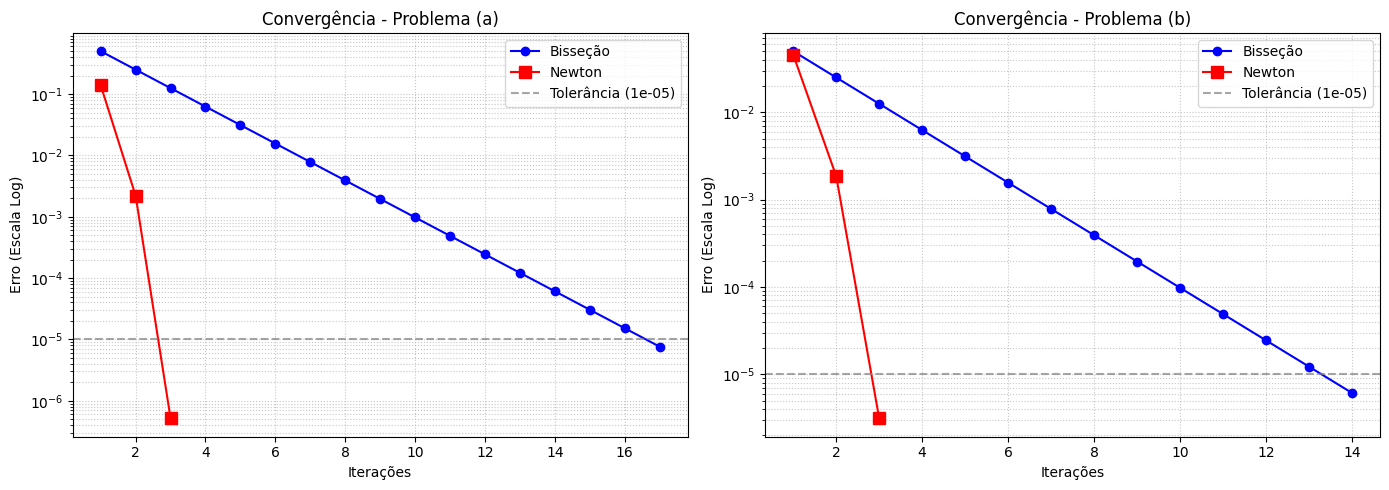

In [10]:
def f_a(x):
    return x - 2**(-x)
def df_a(x):
    return 1 + (2**(-x) * np.log(2))

def f_b(x):
    return x * np.cos(x) - 2*x**2 + 3*x - 1
def df_b(x):
    return np.cos(x) - x * np.sin(x) - 4*x + 3

tolerancia = 1e-5

x0_a = 0.5   
x0_b = 0.25  

raiz_newton_a, hist_newton_a = newton_com_historico(f_a, df_a, x0_a, tol=tolerancia)
raiz_newton_b, hist_newton_b = newton_com_historico(f_b, df_b, x0_b, tol=tolerancia)

_, hist_bis_a = bissecao_com_historico(f_a, 0, 1, tol=tolerancia)
_, hist_bis_b = bissecao_com_historico(f_b, 0.2, 0.3, tol=tolerancia)

print("="*60 + "\nPROBLEMA 3(a) - Método de Newton\n" + "="*60)
print(f"Raiz encontrada: {raiz_newton_a:.6f}")
display(pd.DataFrame(hist_newton_a))

print("\n" + "="*60 + "\nPROBLEMA 3(b) - Método de Newton\n" + "="*60)
print(f"Raiz encontrada: {raiz_newton_b:.6f}")
display(pd.DataFrame(hist_newton_b))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico a
ax1.plot(hist_bis_a['iter'], hist_bis_a['erro_Intervalo'], 'bo-', label='Bisseção')
ax1.plot(hist_newton_a['iter'], hist_newton_a['erro'], 'rs-', markersize=8, label='Newton')
ax1.set_yscale("log")
ax1.axhline(tolerancia, color='gray', linestyle='--', alpha=0.7, label=f'Tolerância ({tolerancia})')
ax1.set_title('Convergência - Problema (a)')
ax1.set_xlabel('Iterações')
ax1.set_ylabel('Erro (Escala Log)')
ax1.grid(True, which='both', linestyle=':', alpha=0.7)
ax1.legend()

# Gráfico b
ax2.plot(hist_bis_b['iter'], hist_bis_b['erro_Intervalo'], 'bo-', label='Bisseção')
ax2.plot(hist_newton_b['iter'], hist_newton_b['erro'], 'rs-', markersize=8, label='Newton')
ax2.set_yscale("log")
ax2.axhline(tolerancia, color='gray', linestyle='--', alpha=0.7, label=f'Tolerância ({tolerancia})')
ax2.set_title('Convergência - Problema (b)')
ax2.set_xlabel('Iterações')
ax2.set_ylabel('Erro (Escala Log)')
ax2.grid(True, which='both', linestyle=':', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

Enquanto a Bisseção faz um trabalho de lento, garantindo o corte do erro pela metade a cada passo e desenhando a reta diagonal clássica da convergência linear, o Método de Newton ataca o problema de forma bem mais rápida, com apenas 3 iterações.

---

Sobre a convergência do método de Newton

__Teorema__: Seja $f \in C^2[a, b]$. Se $p \in (a, b)$ tal que $f(p) = 0$ e $f'(p) \neq 0$, então existe um $\delta > 0$ tal que o método de Newton gera uma sequência $ \left\{ p_n \right\} ^\infty_{n=1}$ convergindo para $p$ para qualquer aproximação inicial $p_0 \in [p - \delta, p + \delta]$.

Este Teorema afirma que, sob hipóteses razoáveis, o método de Newton converge, desde que uma aproximação inicial suficientemente precisa seja escolhida. Este resultado é importante para a teoria do método de Newton, mas raramente é aplicado na prática porque não nos diz como determinar $\delta$.

Recomendação: Vejam a demostração deste teorema, que podem ser encontrada no Capítulo 2 do Burden.

---

## Exercício 10

No notebook disponibilizado para a Aula 8, se faz uso da função `secante` que possui o seguinte cabeçalho: 

```python
def secante(f, x0, x1, tol=1e-10, max_iter=50):
```

A função é importada do arquivo pyNuMeth.py que funciona como um módulo python.
Em sala de aula apresentamos o pseudo código, extraído do Burden, para implementação deste algoritmo.

<img src="figuras/secante.png" alt="Método do Ponto Fixo" width="600">

Modifique seu módulo pyNuMeth.py e implemente nele sua versão do método da secante.

In [11]:
from pyNuMeth import secante ,secante_com_historico, secante_criterios

---

## Exercício 11
Utilize o método da secante para encontrar soluções com precisão de $10^{-5}$ para os os dois problemas apresentados no Exercício 3. Compare as soluções acrescentando o gráfico que mostre a convergência deste método ao gráfico criado no Exercício 9.

PROBLEMA 3(a) - Método da Secante
Raiz encontrada: 0.641186


,iter,x_prev,x_curr,f(x_curr),x_next,erro
0,1,0.000000,1.000000,0.500000,0.666667,0.333333
1,2,1.000000,0.666667,0.036706,0.640257,0.026410
2,3,0.666667,0.640257,-0.001341,0.641188,0.000931
3,4,0.640257,0.641188,0.000004,0.641186,0.000003



PROBLEMA 3(b) - Método da Secante
Raiz encontrada: 0.297530


,iter,x_prev,x_curr,f(x_curr),x_next,erro
0,1,0.200000,0.300000,0.006601,0.297728,2.271586e-03
1,2,0.300000,0.297728,0.000531,0.297530,1.986271e-04
2,3,0.297728,0.297530,-0.000001,0.297530,4.463879e-07


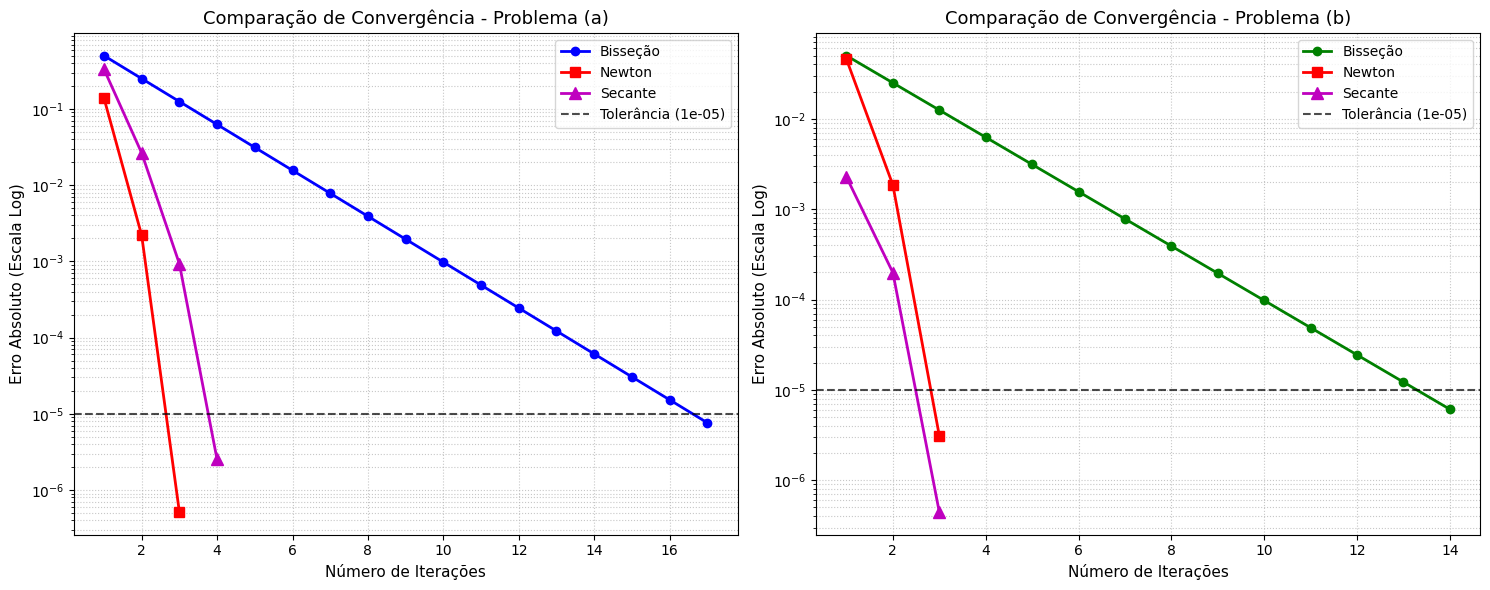

In [12]:
tolerancia = 1e-5

x0_sec_a, x1_sec_a = 0, 1
raiz_sec_a, hist_sec_a = secante_com_historico(f_a, x0_sec_a, x1_sec_a, tol=tolerancia)

x0_sec_b, x1_sec_b = 0.2, 0.3
raiz_sec_b, hist_sec_b = secante_com_historico(f_b, x0_sec_b, x1_sec_b, tol=tolerancia)

print("="*60 + "\nPROBLEMA 3(a) - Método da Secante\n" + "="*60)
print(f"Raiz encontrada: {raiz_sec_a:.6f}")
display(pd.DataFrame(hist_sec_a))

print("\n" + "="*60 + "\nPROBLEMA 3(b) - Método da Secante\n" + "="*60)
print(f"Raiz encontrada: {raiz_sec_b:.6f}")
display(pd.DataFrame(hist_sec_b))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico (a)
ax1.plot(hist_bis_a['iter'], hist_bis_a['erro_Intervalo'], 'bo-', linewidth=2, label='Bisseção')
ax1.plot(hist_newton_a['iter'], hist_newton_a['erro'], 'rs-', linewidth=2, markersize=7, label='Newton')
ax1.plot(hist_sec_a['iter'], hist_sec_a['erro'], 'm^-', linewidth=2, markersize=8, label='Secante')
ax1.set_yscale("log")

ax1.axhline(tolerancia, color='black', linestyle='--', alpha=0.7, label=f'Tolerância ({tolerancia})')
ax1.set_title('Comparação de Convergência - Problema (a)', fontsize=13)
ax1.set_xlabel('Número de Iterações', fontsize=11)
ax1.set_ylabel('Erro Absoluto (Escala Log)', fontsize=11)
ax1.grid(True, which='both', linestyle=':', alpha=0.7)
ax1.legend()

# Gráfico (b)
ax2.plot(hist_bis_b['iter'], hist_bis_b['erro_Intervalo'], 'go-', linewidth=2, label='Bisseção')
ax2.plot(hist_newton_b['iter'], hist_newton_b['erro'], 'rs-', linewidth=2, markersize=7, label='Newton')
ax2.plot(hist_sec_b['iter'], hist_sec_b['erro'], 'm^-', linewidth=2, markersize=8, label='Secante')
ax2.set_yscale("log")

ax2.axhline(tolerancia, color='black', linestyle='--', alpha=0.7, label=f'Tolerância ({tolerancia})')
ax2.set_title('Comparação de Convergência - Problema (b)', fontsize=13)
ax2.set_xlabel('Número de Iterações', fontsize=11)
ax2.set_ylabel('Erro Absoluto (Escala Log)', fontsize=11)
ax2.grid(True, which='both', linestyle=':', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

*   Validação das Taxas de Convergência: O número de iterações comprova perfeitamente a teoria. Enquanto a Bisseção apresentou sua lenta convergência linear (exigindo até 17 iterações), a Secante atingiu a mesma tolerância de $10^{-5}$ em apenas 4 a 5 iterações. O Método de Newton manteve a liderança com apenas 3 iterações
*   Comportamento Gráfico: Fica evidente como a Secante atua como uma ponte entre os outros dois métodos. No primeiro gráfico, sua curva de erro inicia o trajeto com uma inclinação similar à iteração inicial do método da Bisseção, mas rapidamente sofre um decaimento rápido, acompanhando de perto a trajetória vertical típica do Método de Newton.
*   A Relação Custo-Benefício Prática: O aspecto de maior relevância nesta comparação é a vantagem computacional da Secante. Embora requeira uma ou duas iterações a mais do que o Método de Newton para estabilizar na mesma casa decimal, a Secante dispensa o cálculo da derivada $f'(x)$. Na prática, lidamos frequentemente com equações não lineares onde a formulação da derivada é complexa, custosa computacionalmente ou analiticamente indisponível. Nesse cenário, o Método da Secante se torna uma alternativa excepcional, entregando uma velocidade comparável à de Newton sem o ônus da derivada.

In [ ]:
def estimar_ordem(erros):
    erros = np.array(erros, dtype=float)
    ps = []
    for i in range(1, len(erros)-1):
        if erros[i-1] > 0 and erros[i] > 0 and erros[i+1] > 0:
            den = np.log(erros[i]/erros[i-1])
            if abs(den) > 1e-14:
                p = np.log(erros[i+1]/erros[i]) / den
                ps.append(p)
    return ps

# Problema 3(a)
erros_bis_a = hist_bis_a['erro_Intervalo']
erros_newton_a = hist_newton_a['erro']
erros_secante_a = hist_sec_a['erro']

p_bis_a = estimar_ordem(erros_bis_a)
p_newton_a = estimar_ordem(erros_newton_a)
p_secante_a = estimar_ordem(erros_secante_a)

# Problema 3(b)
erros_bis_b = hist_bis_b['erro_Intervalo']
erros_newton_b = hist_newton_b['erro']
erros_secante_b = hist_sec_b['erro']

p_bis_b = estimar_ordem(erros_bis_b)
p_newton_b = estimar_ordem(erros_newton_b)
p_secante_b = estimar_ordem(erros_secante_b)


print("="*60)
print("ESTIMATIVA EMPÍRICA DA ORDEM DE CONVERGÊNCIA (p)")
print("="*60)

# ----------------- PROBLEMA 3(a) -----------------
print("\n" + "-"*40)
print("             PROBLEMA 3(a)")
print("-"*40)

print("\n1. MÉTODO DA BISSEÇÃO (Esperado: p = 1)")
for i, p in enumerate(p_bis_a):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")

print("\n2. MÉTODO DA SECANTE (Esperado: p ≈ 1.618)")
for i, p in enumerate(p_secante_a):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")

print("\n3. MÉTODO DE NEWTON (Esperado: p = 2)")
for i, p in enumerate(p_newton_a):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")


# ----------------- PROBLEMA 3(b) -----------------
print("\n\n" + "-"*40)
print("             PROBLEMA 3(b)")
print("-"*40)

print("\n1. MÉTODO DA BISSEÇÃO (Esperado: p = 1)")
for i, p in enumerate(p_bis_b):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")

print("\n2. MÉTODO DA SECANTE (Esperado: p ≈ 1.618)")
for i, p in enumerate(p_secante_b):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")

print("\n3. MÉTODO DE NEWTON (Esperado: p = 2)")
for i, p in enumerate(p_newton_b):
    print(f"   Iterações {i} a {i+2} -> p ≈ {p:.4f}")

ESTIMATIVA EMPÍRICA DA ORDEM DE CONVERGÊNCIA (p)

----------------------------------------
             PROBLEMA 3(a)
----------------------------------------

1. MÉTODO DA BISSEÇÃO (Esperado: p = 1)
   Iterações 0 a 2 -> p ≈ 1.0000
   Iterações 1 a 3 -> p ≈ 1.0000
   Iterações 2 a 4 -> p ≈ 1.0000
   Iterações 3 a 5 -> p ≈ 1.0000
   Iterações 4 a 6 -> p ≈ 1.0000
   Iterações 5 a 7 -> p ≈ 1.0000
   Iterações 6 a 8 -> p ≈ 1.0000
   Iterações 7 a 9 -> p ≈ 1.0000
   Iterações 8 a 10 -> p ≈ 1.0000
   Iterações 9 a 11 -> p ≈ 1.0000
   Iterações 10 a 12 -> p ≈ 1.0000
   Iterações 11 a 13 -> p ≈ 1.0000
   Iterações 12 a 14 -> p ≈ 1.0000
   Iterações 13 a 15 -> p ≈ 1.0000
   Iterações 14 a 16 -> p ≈ 1.0000

2. MÉTODO DA SECANTE (Esperado: p ≈ 1.618)
   Iterações 0 a 2 -> p ≈ 1.3193
   Iterações 1 a 3 -> p ≈ 1.7680

3. MÉTODO DE NEWTON (Esperado: p = 2)
   Iterações 0 a 2 -> p ≈ 2.0156


----------------------------------------
             PROBLEMA 3(b)
----------------------------------------


---

## Exercício 12

O polinômio de quarto grau

$$
f(x) = 230x^4 + 18x^3 + 9x² - 221x -9
$$

tem dois zeros reais, um em $[ -1, 0]$ e o outro em $[0, 11]$. Tente aproximar esses zeros com uma precisão de $10^{-6}$ usando o

a) método da Secante

b) método de Newton

Use os extremos de cada intervalo como aproximações iniciais em (a) e os pontos médios como aproximação inicial em (b).

RAIZ 1 (Intervalo [-1, 0])
Secante (x0=-1, x1=0): Raiz = -0.0406593 | Iterações = 4


,iter,x_prev,x_curr,f(x_curr),x_next,erro
0,1,-1.000000,0.000000,-9.000000,-0.020362,2.036199e-02
1,2,0.000000,-0.020362,-4.496381,-0.040691,2.032927e-02
2,3,-0.020362,-0.040691,0.007087,-0.040659,3.199386e-05
3,4,-0.040691,-0.040659,-0.000006,-0.040659,2.573803e-08



Newton (x0=-0.5): Raiz = -0.0406593 | Iterações = 4


,iter,x,f(x),f'(x),x_next,erro
0,1,-0.500000,115.875000,-331.500000,-0.150452,3.495475e-01
1,2,-0.150452,24.510271,-225.618988,-0.041817,1.086357e-01
2,3,-0.041817,0.256641,-221.725549,-0.040659,1.157470e-03
3,4,-0.040659,0.000012,-221.704436,-0.040659,5.518157e-08




RAIZ 2 (Intervalo [0, 11])
Secante (x0=0, x1=11): Raiz = -0.0406593 | Iterações = 5


,iter,x_prev,x_curr,f(x_curr),x_next,erro
0,1,0.000000,11.000000,3.390037e+06,0.000029,1.099997e+01
1,2,11.000000,0.000029,-9.006454e+00,0.000058,2.922401e-05
2,3,0.000029,0.000058,-9.012912e+00,-0.040724,4.078255e-02
3,4,0.000058,-0.040724,1.437513e-02,-0.040659,6.494250e-05
4,5,-0.040724,-0.040659,-2.294613e-05,-0.040659,1.034985e-07



Newton (x0=5.5): Raiz = 0.9623984 | Iterações = 11


,iter,x,f(x),f'(x),x_next,erro
0,1,5.500000,2.125069e+05,154576.500000,4.125232,1.374768e+00
1,2,4.125232,6.710331e+04,65357.379106,3.098518,1.026714e+00
2,3,3.098518,2.112850e+04,27721.650161,2.336352,7.621660e-01
3,4,2.336352,6.606352e+03,11848.642807,1.778790,5.575619e-01
4,5,1.778790,2.030316e+03,5159.878167,1.385309,3.934814e-01
5,6,1.385309,5.970316e+02,2353.402860,1.131620,2.536887e-01
6,7,1.131620,1.556851e+02,1201.702401,1.002066,1.295538e-01
7,8,1.002066,2.859921e+01,776.975065,0.965258,3.680840e-02
8,9,0.965258,1.916495e+00,674.091987,0.962415,2.843076e-03
9,10,0.962415,1.086631e-02,666.455251,0.962398,1.630463e-05


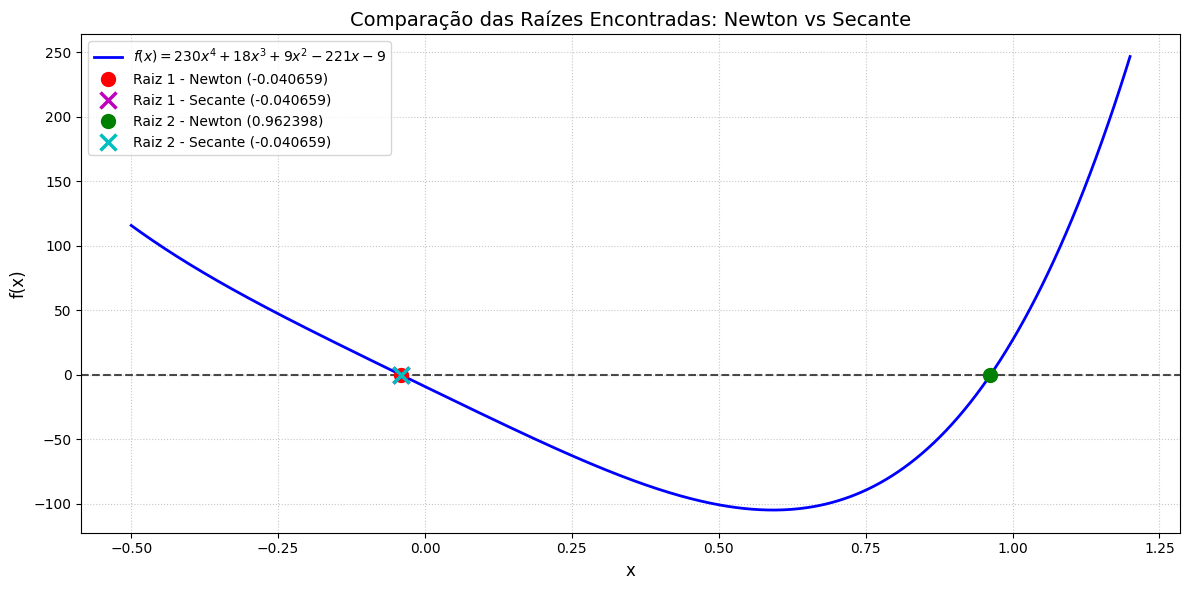

In [13]:
def f_12(x):
    return 230*x**4 + 18*x**3 + 9*x**2 - 221*x - 9

def df_12(x):
    return 920*x**3 + 54*x**2 + 18*x - 221

tolerancia = 1e-6

raiz_sec_1, hist_sec_1 = secante_com_historico(f_12, -1, 0, tol=tolerancia)
raiz_sec_2, hist_sec_2 = secante_com_historico(f_12, 0, 11, tol=tolerancia)

raiz_newton_1, hist_newton_1 = newton_com_historico(f_12, df_12, -0.5, tol=tolerancia)
raiz_newton_2, hist_newton_2 = newton_com_historico(f_12, df_12, 5.5, tol=tolerancia)

print("="*70)
print(f"RAIZ 1 (Intervalo [-1, 0])")
print("="*70)
print(f"Secante (x0=-1, x1=0): Raiz = {raiz_sec_1:.7f} | Iterações = {len(hist_sec_1['iter'])}")
display(pd.DataFrame(hist_sec_1))

print(f"\nNewton (x0=-0.5): Raiz = {raiz_newton_1:.7f} | Iterações = {len(hist_newton_1['iter'])}")
display(pd.DataFrame(hist_newton_1))

print("\n\n" + "="*70)
print(f"RAIZ 2 (Intervalo [0, 11])")
print("="*70)
print(f"Secante (x0=0, x1=11): Raiz = {raiz_sec_2:.7f} | Iterações = {len(hist_sec_2['iter'])}")
display(pd.DataFrame(hist_sec_2))

print(f"\nNewton (x0=5.5): Raiz = {raiz_newton_2:.7f} | Iterações = {len(hist_newton_2['iter'])}")
display(pd.DataFrame(hist_newton_2))

# Gráfico
x_plot = np.linspace(-0.5, 1.2, 500)
y_plot = f_12(x_plot)

plt.figure(figsize=(12, 6))
plt.plot(x_plot, y_plot, 'b-', linewidth=2, label=r'$f(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9$')
plt.axhline(0, color='black', linestyle='--', alpha=0.7)

plt.plot(raiz_newton_1, 0, 'ro', markersize=10, 
         label=f'Raiz 1 - Newton ({raiz_newton_1:.6f})')
plt.plot(raiz_sec_1, 0, 'mx', markersize=12, markeredgewidth=2.5, 
         label=f'Raiz 1 - Secante ({raiz_sec_1:.6f})')

plt.plot(raiz_newton_2, 0, 'go', markersize=10, 
         label=f'Raiz 2 - Newton ({raiz_newton_2:.6f})')
plt.plot(raiz_sec_2, 0, 'cx', markersize=12, markeredgewidth=2.5, 
         label=f'Raiz 2 - Secante ({raiz_sec_2:.6f})')


plt.title('Comparação das Raízes Encontradas: Newton vs Secante', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('f(x)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

1. Convergência em vizinhança favorável (Intervalo $[-1, 0]$)

Quando a região de busca apresenta um comportamento regular e os valores iniciais estão próximos da verdadeira raiz ($-1$ e $0$ para a Secante; $-0.5$ para Newton), observamos a eficiência esperada. Ambos os métodos convergiram com estabilidade para a raiz $x \approx -0.0406593$ em apenas 4 iterações.

2. A influência da escala e do domínio amplo (Intervalo $[0, 11]$)

O segundo intervalo proposto impõe um desafio computacional, evidenciando as limitações dos métodos baseados em aproximações lineares ao longo de domínios muito extensos.
*   O custo de deslocamento em Newton: Iniciando no ponto médio $x_0 = 5.5$, o Método de Newton demandou 11 iterações para convergir à raiz $x \approx 0.9623984$. Nesse ponto inicial, a magnitude da função ($f \approx 2.12 \times 10^5$) e a inclinação da reta tangente são colossais. O método foi forçado a realizar um longo percurso de aproximação ao longo da curva. Ele não divergiu graças à convexidade do polinômio na região, mas sofreu uma penalidade clara de eficiência devido à distância do chute inicial.
*   A divergência de bacia na Secante: O comportamento do Método da Secante neste intervalo é tecnicamente muito explicativo. Ao analisar a tabela, nota-se que o método não encontrou a raiz em $[0, 11]$, convergindo inesperadamente para a raiz negativa ($-0.0406593$). Esse fenômeno ocorre devido à discrepância extrema entre as ordenadas dos pontos iniciais: a reta secante que conecta os pontos $(0, -9)$ e $(11, \approx 3.39 \times 10^6)$ possui uma inclinação tão acentuada que atinge o eixo horizontal muito próximo à origem ($x_2 \approx 0.000029$). Ao ser projetado para essa coordenada, o algoritmo foi capturado pela bacia de atração da raiz negativa, falhando na busca pela solução original.

---

## Exercício 13

No Exercício 4 foi discutido os possíveis critério de parada do algoritmo da bisseção. A proposta sugerida é de que, dado um valor $\epsilon > 0$ podemos gerar uma sequência de aproximações $p_1, p_2, \dots, p_N$ até que uma das seguintes condições seja satisfeita:

$$
\left | P_N - P_{N-1} \right | < \epsilon, 
$$

$$
\frac{\left | P_N - P_{N-1} \right |}{\left | P_N \right |} < \epsilon,
$$

$$
\left | f(P_N) \right | < \epsilon.
$$

a) Nos pseudo códigos propostos para os métodos de Newton e da secante se utiliza uma destas abordagens. Qual? Explique.

b) Crie uma versão das funções `newton` e `secante` que permita selecionar entre cada um destes três critérios de parada. Avalie o resultado do Exercício 3.a com cada um dos critérios, para cada um destes métods, e discuta o resultado.

In [14]:
def f_a(x):
    return x - 2**(-x)

def df_a(x):
    return 1 + (2**(-x) * np.log(2))

tolerancia = 1e-5

print("="*70)
print(" "*20 + "MÉTODO DE NEWTON (x0 = 0.5)")
print("="*70)

# Critério 1: 
raiz_n1, hist_n1 = newton_criterios(f_a, df_a, 0.5, tol=tolerancia, criterio=1)
df_n1 = pd.DataFrame(hist_n1)
print("\n" + "-"*60)
print(f"CRITÉRIO 1: Diferença Absoluta |Pn - Pn-1| < {tolerancia}")
print(f"Raiz: {raiz_n1:.6f} | Iterações: {len(df_n1)}")
display(df_n1.tail()) 

# Critério 2: 
raiz_n2, hist_n2 = newton_criterios(f_a, df_a, 0.5, tol=tolerancia, criterio=2)
df_n2 = pd.DataFrame(hist_n2)
print("\n" + "-"*60)
print(f"CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < {tolerancia}")
print(f"Raiz: {raiz_n2:.6f} | Iterações: {len(df_n2)}")
display(df_n2.tail())

# Critério 3: 
raiz_n3, hist_n3 = newton_criterios(f_a, df_a, 0.5, tol=tolerancia, criterio=3)
df_n3 = pd.DataFrame(hist_n3)
print("\n" + "-"*60)
print(f"CRITÉRIO 3: Valor da Função |f(Pn)| < {tolerancia}")
print(f"Raiz: {raiz_n3:.6f} | Iterações: {len(df_n3)}")
display(df_n3.tail())

print("\n\n" + "="*70)
print(" "*18 + "MÉTODO DA SECANTE (x0 = 0, x1 = 1)")
print("="*70)

# Critério 1
raiz_s1, hist_s1 = secante_criterios(f_a, 0, 1, tol=tolerancia, criterio=1)
df_s1 = pd.DataFrame(hist_s1)
print("\n" + "-"*60)
print(f"CRITÉRIO 1: Diferença Absoluta |Pn - Pn-1| < {tolerancia}")
print(f"Raiz: {raiz_s1:.6f} | Iterações: {len(df_s1)}")
display(df_s1.tail())

# Critério 2
raiz_s2, hist_s2 = secante_criterios(f_a, 0, 1, tol=tolerancia, criterio=2)
df_s2 = pd.DataFrame(hist_s2)
print("\n" + "-"*60)
print(f"CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < {tolerancia}")
print(f"Raiz: {raiz_s2:.6f} | Iterações: {len(df_s2)}")
display(df_s2.tail())

# Critério 3
raiz_s3, hist_s3 = secante_criterios(f_a, 0, 1, tol=tolerancia, criterio=3)
df_s3 = pd.DataFrame(hist_s3)
print("\n" + "-"*60)
print(f"CRITÉRIO 3: Valor da Função |f(Pn)| < {tolerancia}")
print(f"Raiz: {raiz_s3:.6f} | Iterações: {len(df_s3)}")
display(df_s3.tail())

                    MÉTODO DE NEWTON (x0 = 0.5)

------------------------------------------------------------
CRITÉRIO 1: Diferença Absoluta |Pn - Pn-1| < 1e-05
Raiz: 0.641186 | Iterações: 3


,iter,x,valor_criterio
0,1,0.638986,1.389858e-01
1,2,0.641185,2.199428e-03
2,3,0.641186,5.163778e-07



------------------------------------------------------------
CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < 1e-05
Raiz: 0.641186 | Iterações: 3


,iter,x,valor_criterio
0,1,0.638986,2.175100e-01
1,2,0.641185,3.430254e-03
2,3,0.641186,8.053481e-07



------------------------------------------------------------
CRITÉRIO 3: Valor da Função |f(Pn)| < 1e-05
Raiz: 0.641185 | Iterações: 2


,iter,x,valor_criterio
0,1,0.638986,3.178425e-03
1,2,0.641185,7.458747e-07


... (2 outputs left out)


------------------------------------------------------------
CRITÉRIO 2: Diferença Relativa |Pn - Pn-1|/|Pn| < 1e-05
Raiz: 0.641186 | Iterações: 4


,iter,x_next,valor_criterio
0,2,0.666667,0.500000
1,3,0.640257,0.041248
2,4,0.641188,0.001452
3,5,0.641186,0.000004



------------------------------------------------------------
CRITÉRIO 3: Valor da Função |f(Pn)| < 1e-05
Raiz: 0.641188 | Iterações: 3


,iter,x_next,valor_criterio
0,2,0.666667,0.036706
1,3,0.640257,0.001341
2,4,0.641188,0.000004


a) O critério adotado nos pseudocódigos

Nos algoritmos de Newton e da Secante, a abordagem utilizada é o Critério 1 (Diferença Absoluta: $|P_N - P_{N-1}| < \epsilon$).

Já que, este critério mede essencialmente o "tamanho do passo" da iteração. Ele é o padrão porque avalia a estabilidade geométrica da sequência diretamente no domínio (o eixo $x$). Se o método tenta dar um passo que é menor do que a nossa tolerância, assumimos que ele ancorou na raiz. É uma escolha mais conservadora e robusta que o Critério 3 (que pode gerar falsos positivos se a curva da função for muito suave e cruzar o eixo de forma "plana") e não exige o conhecimento prévio da escala da raiz, ao contrário do Critério 2.

b) Análise comparativa dos critérios de parada (Newton e Secante)

A leitura das tabelas geradas revela um contraste em relação ao comportamento observado no método da bisseção.
*   O achatamento do esforço computacional: Na bisseção, mudar o critério poderia custar várias iterações adicionais. Aqui, o impacto é quase nulo. Devido à altíssima velocidade de convergência na vizinhança da raiz, o erro despenca de forma abrupta. Vemos que os Critérios 1 e 2 foram satisfeitos exatamente na mesma etapa (3 iterações para Newton, 4 para a Secante). Quando a convergência é tão aguda, o método "destrói" todas as métricas de erro simultaneamente.
*   A "pressa" do Critério 3: Um detalhe interessante surge ao analisarmos o Critério 3 (Resíduo da Função). Em ambos os métodos, ele antecipou a parada em uma iteração (encerrou Newton na 2ª e Secante na 3ª). Isso demonstra que a função $f(x)$ mergulha abaixo do limiar de $10^{-5}$ um instante antes da coordenada $x$ se estabilizar completamente. O resultado dessa parada precoce é uma raiz ligeiramente menos refinada na última casa decimal (Newton retornou $0.641185$ no Critério 3, enquanto os demais garantiram o assentamento em $0.641186$)